# Trabajo Práctico Clase 6: Aprendizaje Supervisado Aplicado a Reclamos de Gas

## 1. Contexto y Pregunta de Investigación
En el marco de la cadena de valor del gas natural en Argentina y la tutela regulatoria del ENARGAS, se analizan los reclamos a distribuidoras en 2026.

* **Pregunta de Investigación:** ¿Es posible predecir si un reclamo de gas será procedente (favorable al usuario) o improcedente a partir de la prestadora, la vía de ingreso, el motivo técnico y el volumen acumulado?
* **Tarea:** Clasificación binaria supervisada.
* **Variable Objetivo ($y$):** `reclamo_resolucion` (Procedente / Improcedente).
* **Modelos a contrastar:**
  1. Árbol de Decisión (`DecisionTreeClassifier`)
  2. Máquina de Vectores de Soporte (`SVC`)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Como el archivo está en la misma carpeta Clase_6, lo leemos directamente
df = pd.read_csv('reclamos_prestadoras_2026.csv')

print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")
print("\nPrimeras 5 filas:")
df.head()

Dimensiones del dataset: 3454 filas y 9 columnas.

Primeras 5 filas:


,reclamo_ano,reclamo_mes_nro,reclamo_mes_nombre,reclamo_prestadora,reclamo_provincia,reclamo_grupo,reclamo_via_ingreso,reclamo_resolucion,reclamo_cantidad
0,2026,1,Enero,Camuzzi Gas del Sur S.A.,Chubut,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Procedente,3
1,2026,1,Enero,Camuzzi Gas del Sur S.A.,Río Negro,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Procedente,5
2,2026,1,Enero,Camuzzi Gas del Sur S.A.,Chubut,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Improcedente,4
3,2026,1,Enero,Camuzzi Gas del Sur S.A.,Tierra del Fuego Antártida e Islas del Atlánti...,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Improcedente,6
4,2026,1,Enero,Camuzzi Gas del Sur S.A.,Santa Cruz,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Improcedente,4


In [2]:
# Verificamos si existen valores nulos
print("Valores nulos por columna:")
print(df.isnull().sum())

# Analizamos la distribución de la variable a predecir
print("\nDistribución de la variable objetivo:")
print(df['reclamo_resolucion'].value_counts())
print("\nPorcentajes:")
print(df['reclamo_resolucion'].value_counts(normalize=True).round(4) * 100)

Valores nulos por columna:
reclamo_ano            0
reclamo_mes_nro        0
reclamo_mes_nombre     0
reclamo_prestadora     0
reclamo_provincia      0
reclamo_grupo          0
reclamo_via_ingreso    0
reclamo_resolucion     0
reclamo_cantidad       0
dtype: int64

Distribución de la variable objetivo:
reclamo_resolucion
Improcedente    1956
Procedente      1498
Name: count, dtype: int64

Porcentajes:
reclamo_resolucion
Improcedente    56.63
Procedente      43.37
Name: proportion, dtype: float64


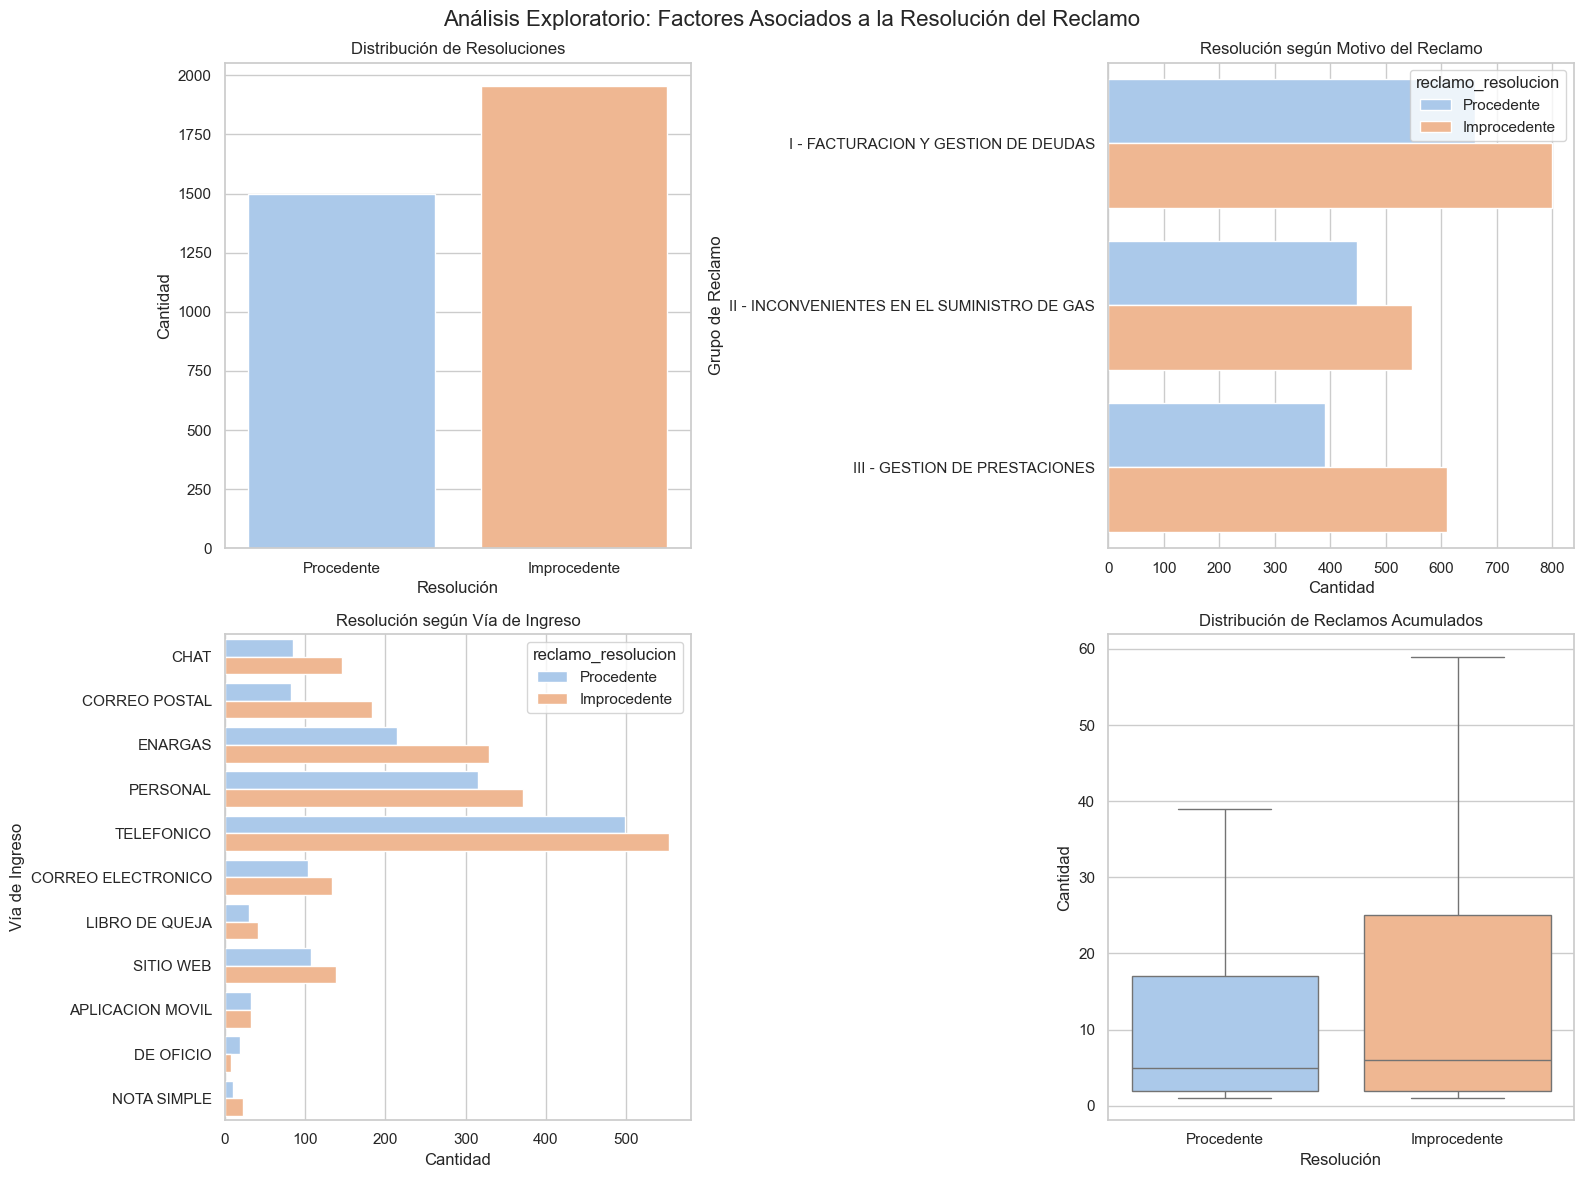

In [4]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

sns.set_theme(style="whitegrid")
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
fig.suptitle('Análisis Exploratorio: Factores Asociados a la Resolución del Reclamo', fontsize=16)

# 1. Balance de la variable objetivo
sns.countplot(x='reclamo_resolucion', data=df, ax=axs[0, 0], palette='pastel')
axs[0, 0].set_title('Distribución de Resoluciones', fontsize=12)
axs[0, 0].set_xlabel('Resolución')
axs[0, 0].set_ylabel('Cantidad')

# 2. Resolución por Tipo de Reclamo (Grupo)
sns.countplot(y='reclamo_grupo', hue='reclamo_resolucion', data=df, ax=axs[0, 1], palette='pastel')
axs[0, 1].set_title('Resolución según Motivo del Reclamo', fontsize=12)
axs[0, 1].set_xlabel('Cantidad')
axs[0, 1].set_ylabel('Grupo de Reclamo')

# 3. Resolución por Vía de Ingreso
sns.countplot(y='reclamo_via_ingreso', hue='reclamo_resolucion', data=df, ax=axs[1, 0], palette='pastel')
axs[1, 0].set_title('Resolución según Vía de Ingreso', fontsize=12)
axs[1, 0].set_xlabel('Cantidad')
axs[1, 0].set_ylabel('Vía de Ingreso')

# 4. Boxplot de cantidad de casos acumulados por resolución
sns.boxplot(x='reclamo_resolucion', y='reclamo_cantidad', data=df, ax=axs[1, 1], palette='pastel', showfliers=False)
axs[1, 1].set_title('Distribución de Reclamos Acumulados', fontsize=12)
axs[1, 1].set_xlabel('Resolución')
axs[1, 1].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

## 2. Preparación de los Datos y Partición
* Mapeamos la variable objetivo: `Procedente = 1`, `Improcedente = 0`.
* Aplicamos One-Hot Encoding a las variables categóricas nominales para evitar falsos órdenes numéricos.
* Dividimos en 80% para entrenamiento y 20% para prueba con estratificación.
* Escalamos las variables numéricas con `StandardScaler`, paso crítico para el cálculo de distancias y márgenes en Support Vector Machine (SVM).

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Definición de objetivo (1: Procedente, 0: Improcedente)
y = df['reclamo_resolucion'].map({'Procedente': 1, 'Improcedente': 0})

# 2. Selección de predictoras
columnas_predictoras = [
    'reclamo_cantidad', 
    'reclamo_mes_nro', 
    'reclamo_prestadora', 
    'reclamo_provincia', 
    'reclamo_grupo', 
    'reclamo_via_ingreso'
]
X_crudo = df[columnas_predictoras]

# 3. One-Hot Encoding
X = pd.get_dummies(X_crudo, drop_first=True)

# 4. División 80/20 estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Escalado para SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Muestras de entrenamiento: {X_train.shape[0]}")
print(f"Muestras de prueba: {X_test.shape[0]}")
print(f"Total de variables predictoras resultantes: {X.shape[1]}")

Muestras de entrenamiento: 2763
Muestras de prueba: 691
Total de variables predictoras resultantes: 45


In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# Modelo 1: Árbol de Decisión (con max_depth controlado para evitar sobreajuste)
arbol = DecisionTreeClassifier(max_depth=4, random_state=42)
arbol.fit(X_train, y_train)

# Modelo 2: Support Vector Machine (con kernel RBF)
svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train_scaled, y_train)

# Evaluación con .score()
print("=== EXACTITUD (ACCURACY) ===")
print(f"Árbol de Decisión - Train: {arbol.score(X_train, y_train):.4f} | Test: {arbol.score(X_test, y_test):.4f}")
print(f"SVM (Kernel RBF)   - Train: {svm.score(X_train_scaled, y_train):.4f} | Test: {svm.score(X_test_scaled, y_test):.4f}")

# Reporte detallado en conjunto de prueba
print("\n=== REPORTE DE CLASIFICACIÓN: ÁRBOL DE DECISIÓN ===")
print(classification_report(y_test, arbol.predict(X_test), target_names=['Improcedente', 'Procedente']))

print("\n=== REPORTE DE CLASIFICACIÓN: SVM ===")
print(classification_report(y_test, svm.predict(X_test_scaled), target_names=['Improcedente', 'Procedente']))

=== EXACTITUD (ACCURACY) ===
Árbol de Decisión - Train: 0.6008 | Test: 0.6006
SVM (Kernel RBF)   - Train: 0.6037 | Test: 0.5427

=== REPORTE DE CLASIFICACIÓN: ÁRBOL DE DECISIÓN ===
              precision    recall  f1-score   support

Improcedente       0.60      0.89      0.72       391
  Procedente       0.61      0.22      0.32       300

    accuracy                           0.60       691
   macro avg       0.60      0.56      0.52       691
weighted avg       0.60      0.60      0.55       691


=== REPORTE DE CLASIFICACIÓN: SVM ===
              precision    recall  f1-score   support

Improcedente       0.57      0.82      0.67       391
  Procedente       0.43      0.18      0.25       300

    accuracy                           0.54       691
   macro avg       0.50      0.50      0.46       691
weighted avg       0.51      0.54      0.49       691

